In [1]:
print("Nama  : Salsabila Anggrayni")
print("NPM   : 11124270")
print("Kelas : 3KA31")

Nama  : Salsabila Anggrayni
NPM   : 11124270
Kelas : 3KA31


Import library

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

Load data

In [3]:
FILE = "paket_a_transaksi_pos_2024_2025.csv"
df = pd.read_csv(FILE)
print("Jumlah baris awal:", len(df))

Jumlah baris awal: 5030


Pembersihan data

In [4]:
# a) Hapus baris duplikat persis
df = df.drop_duplicates().copy()

# b) Rapikan kode produk (ada spasi di depan & huruf kecil)
df["kode_produk"] = df["kode_produk"].str.strip().str.upper()

# c) Buang kode produk tidak valid (XXX....)
df = df[~df["kode_produk"].str.startswith("XXX")]

# d) Rapikan status
df["status"] = df["status"].str.strip().str.upper()

# e) Tanggal: formatnya campur (YYYY-MM-DD, DD-MM-YYYY, DD/MM/YYYY)
def parse_tanggal(s):
    s = str(s).strip()
    if s[4] == "-":                                   # 2025-06-02
        return pd.to_datetime(s, format="%Y-%m-%d", errors="coerce")
    s = s.replace("/", "-")                           # 26/03/2025 -> 26-03-2025
    return pd.to_datetime(s, format="%d-%m-%Y", errors="coerce")

df["tanggal"] = df["tanggal"].apply(parse_tanggal)
df = df.dropna(subset=["tanggal"])

# f) Harga: ada format "7500,00" dan "13.500" -> jadi angka
def parse_harga(x):
    x = str(x).strip()
    if "," in x:                                      # 7500,00 -> 7500
        x = x.split(",")[0]
    x = x.replace(".", "")                            # 13.500 -> 13500
    return float(x)

df["harga_satuan"] = df["harga_satuan"].apply(parse_harga)

# g) Jumlah: buang nilai <= 0 dan outlier ekstrem
#    (median jumlah beli hanya 2; nilai ratusan-ribuan = salah input)
BATAS_JUMLAH = 100
df = df[(df["jumlah"] > 0) & (df["jumlah"] <= BATAS_JUMLAH)]

# h) Hitung nilai penjualan setelah diskon
df["total"] = df["jumlah"] * df["harga_satuan"] * (1 - df["diskon_persen"] / 100)

df["tahun"] = df["tanggal"].dt.year
print("Jumlah baris setelah dibersihkan:", len(df))

# Data khusus 2025
df25 = df[df["tahun"] == 2025]

# Formatter angka Rupiah (juta) -> sumbu Y jadi "10 jt", "12 jt", dst.
fmt_juta = FuncFormatter(lambda x, _: f"{x/1e6:,.0f} jt")

Jumlah baris setelah dibersihkan: 4894


Dashboard 2×2

Korelasi jumlah beli vs diskon: -0.015


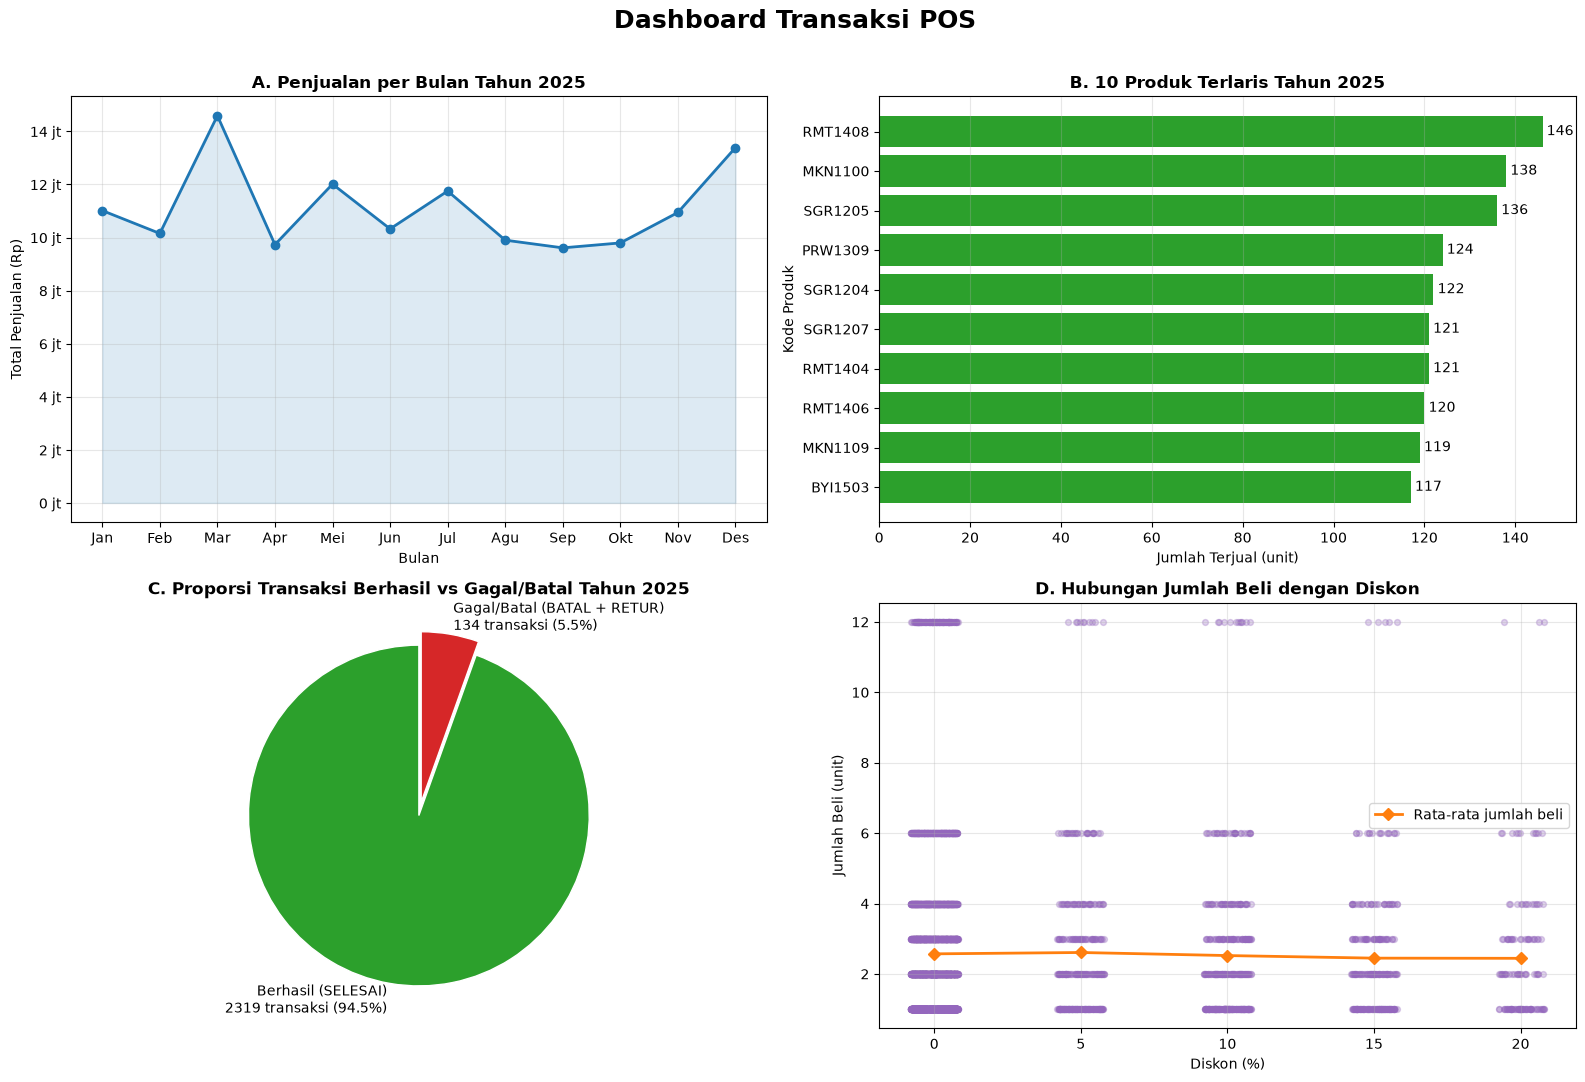

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
fig.suptitle("Dashboard Transaksi POS", fontsize=18, fontweight="bold")

# ---------- A. Penjualan per bulan tahun 2025 ----------
ax = axes[0, 0]
jual_bulan = (df25[df25["status"] == "SELESAI"]
              .groupby(df25["tanggal"].dt.month)["total"].sum()
              .reindex(range(1, 13), fill_value=0))
nama_bulan = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun",
              "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]
ax.plot(nama_bulan, jual_bulan.values, marker="o", linewidth=2, color="#1f77b4")
ax.fill_between(nama_bulan, jual_bulan.values, alpha=0.15, color="#1f77b4")
ax.set_title("A. Penjualan per Bulan Tahun 2025", fontweight="bold")
ax.set_xlabel("Bulan")
ax.set_ylabel("Total Penjualan (Rp)")
ax.yaxis.set_major_formatter(fmt_juta)
ax.grid(alpha=0.3)

# ---------- B. 10 produk terlaris tahun 2025 ----------
ax = axes[0, 1]
top10 = (df25[df25["status"] == "SELESAI"]
         .groupby("kode_produk")["jumlah"].sum()
         .sort_values(ascending=False).head(10)
         .sort_values())                              # supaya terbesar di atas
bars = ax.barh(top10.index, top10.values, color="#2ca02c")
ax.bar_label(bars, padding=3)
ax.set_title("B. 10 Produk Terlaris Tahun 2025", fontweight="bold")
ax.set_xlabel("Jumlah Terjual (unit)")
ax.set_ylabel("Kode Produk")
ax.grid(axis="x", alpha=0.3)

# ---------- C. Proporsi transaksi berhasil vs gagal/batal 2025 ----------
# Berhasil = SELESAI ; Gagal/Batal = BATAL + RETUR
ax = axes[1, 0]
berhasil = (df25["status"] == "SELESAI").sum()
gagal = df25["status"].isin(["BATAL", "RETUR"]).sum()
total_trx = berhasil + gagal
ax.pie([berhasil, gagal],
       labels=[f"Berhasil (SELESAI)\n{berhasil} transaksi ({berhasil/total_trx:.1%})",
               f"Gagal/Batal (BATAL + RETUR)\n{gagal} transaksi ({gagal/total_trx:.1%})"],
       startangle=90, colors=["#2ca02c", "#d62728"],
       explode=(0, 0.08), wedgeprops={"edgecolor": "white"})
ax.set_title("C. Proporsi Transaksi Berhasil vs Gagal/Batal Tahun 2025",
             fontweight="bold")

# ---------- D. Hubungan jumlah beli dengan diskon ----------
# Diskon hanya bernilai 0/5/10/15/20, jadi titik diberi sedikit jitter
ax = axes[1, 1]
rng = np.random.default_rng(42)
x = df["diskon_persen"] + rng.uniform(-0.8, 0.8, len(df))
ax.scatter(x, df["jumlah"], alpha=0.3, s=18, color="#9467bd")
rata = df.groupby("diskon_persen")["jumlah"].mean()
ax.plot(rata.index, rata.values, color="#ff7f0e", marker="D",
        linewidth=2, label="Rata-rata jumlah beli")
ax.set_title("D. Hubungan Jumlah Beli dengan Diskon", fontweight="bold")
ax.set_xlabel("Diskon (%)")
ax.set_ylabel("Jumlah Beli (unit)")
ax.set_xticks([0, 5, 10, 15, 20])
ax.legend()
ax.grid(alpha=0.3)

# Korelasi (angka pendukung untuk bagian D)
korelasi = df["jumlah"].corr(df["diskon_persen"])
print(f"Korelasi jumlah beli vs diskon: {korelasi:.3f}")

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.savefig("visualisasi_psd.png", dpi=150)           # simpan gambar (opsional)
plt.show()